# Maximum Flow (Kattis: `maxflow`)
Disclaimer: The notes are AI generated. The solution is not.


Notation follows Kleinberg & Tardos, *Algorithm Design*, Chapter 7.

**Contents**
1. The task in our own words
2. What is a maximum flow?
3. First idea: greedy, and why it fails
4. The residual graph
5. The algorithm: Ford–Fulkerson
6. Why the answer is optimal: max-flow = min-cut
7. Running time and how to choose the path (Edmonds–Karp)
8. Details specific to this Kattis problem
9. Roadmap for the code

### Problem statement

### 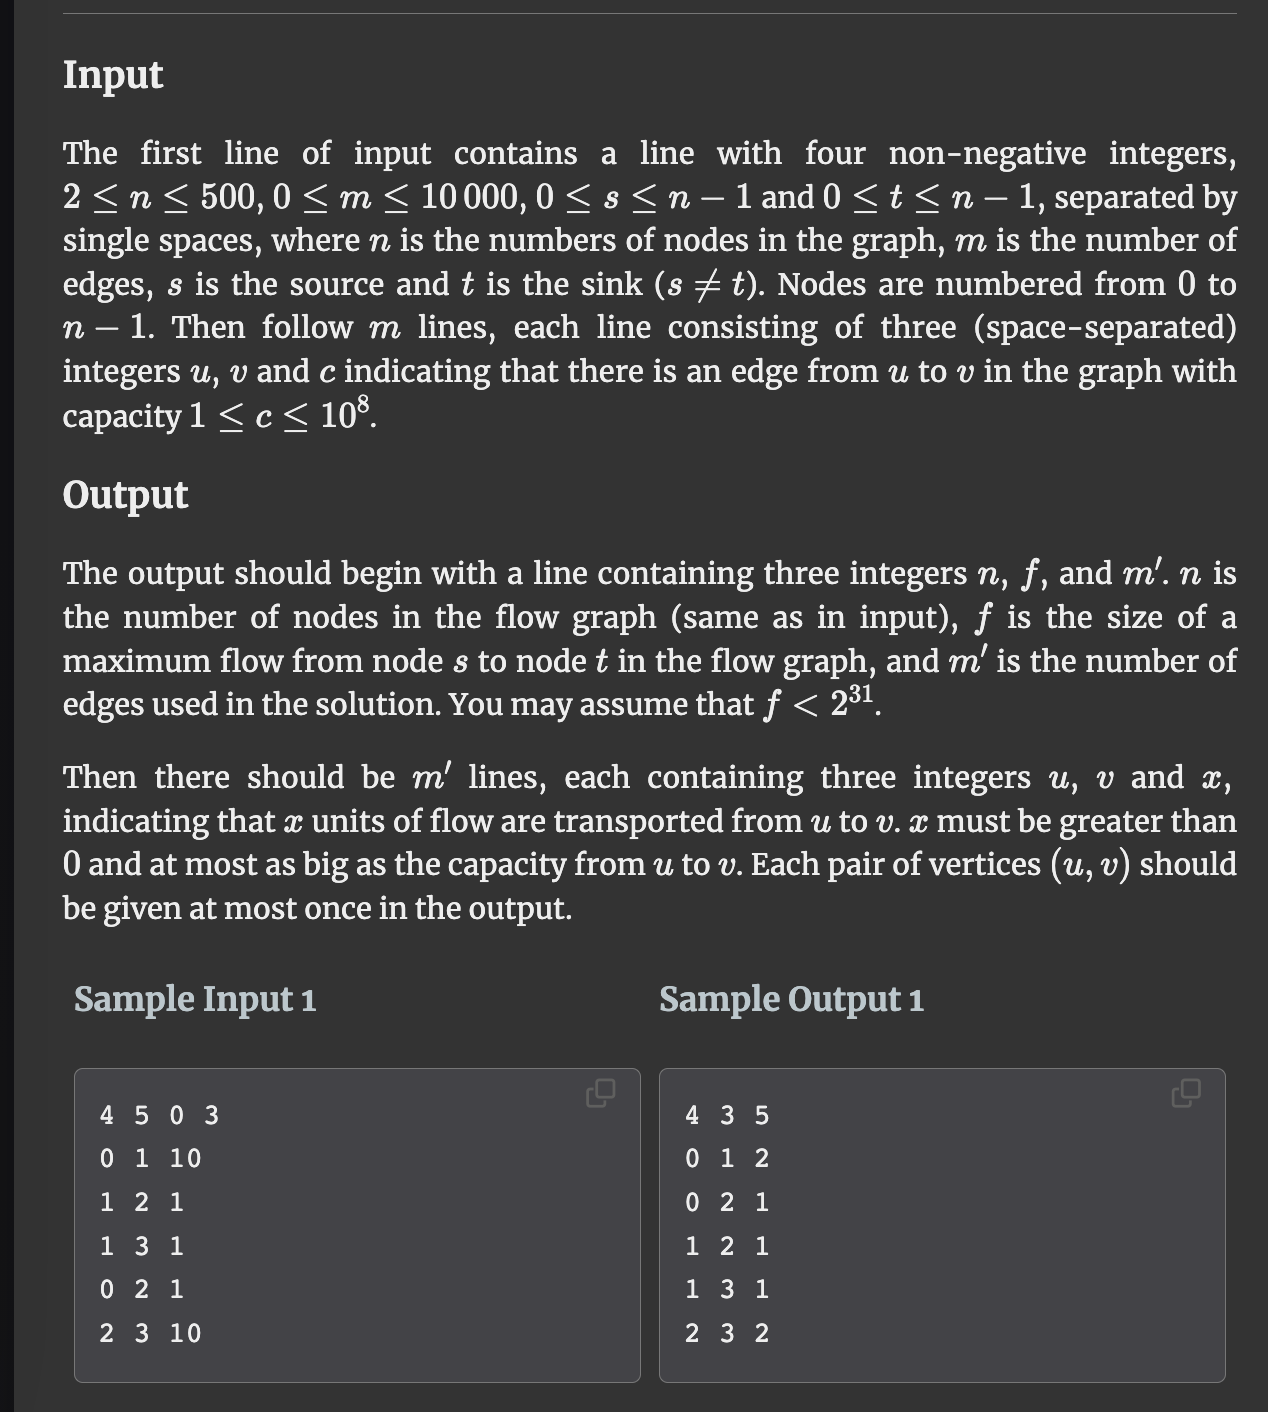

## 1. The task in our own words

We get a **directed graph** with $n \le 500$ nodes and $m \le 10\,000$ edges. Every edge $u \to v$ has a **capacity** $c$: how much can be sent through it. We must:

1. compute the **maximum amount of flow** $f$ that can be sent from the source $s$ to the sink $t$, and
2. print **one concrete flow** that achieves it: for every edge that carries flow, how much it carries.

Sample 1 drawn as a graph ($s = 0$, $t = 3$). All diagonal edges point left to right, and the middle edge points down ($1 \to 2$):

```
                (1)
         10   /  |  \   1
            /    |    \
        (0)      | 1   (3)
            \    |    /
         1    \  v  /   10
                (2)
```

The answer is $f = 3$. Even though $0$ could send out $10 + 1 = 11$, node $3$ can receive at most $1$ from node $1$ plus whatever reaches node $2$, and node $2$ can receive at most $1 + 1 = 2$. So $1 + 2 = 3$ is the limit.

## 2. What is a maximum flow?

**Flow network.** A directed graph $G = (V, E)$ with
- a **source** $s$ (where flow is produced) and a **sink** $t$ (where flow is consumed),
- a **capacity** $c(e) \ge 0$ on every edge $e$.

Think of water pipes: $c(e)$ is how many litres per second pipe $e$ can carry.

**Flow.** A flow assigns a number $f(e)$ to every edge such that

1. **Capacity constraint:** $0 \le f(e) \le c(e)$ for every edge, so no pipe is overfilled.
2. **Flow conservation:** for every node $v \ne s, t$
$$\sum_{e \text{ into } v} f(e) \;=\; \sum_{e \text{ out of } v} f(e)$$
   What comes in must go out: inner nodes neither store nor create flow.

**Value of a flow.** $v(f)$ = the net amount of flow leaving $s$. By conservation this is the same as the net amount arriving at $t$.

**Maximum flow problem:** find a flow $f$ with the largest possible value $v(f)$.

*Check with the sample output:* node 1 receives $2$ (from 0) and sends $1 + 1 = 2$ (to 2 and 3) ✓. Node 2 receives $1 + 1 = 2$ and sends $2$ ✓. Value $= 2 + 1 = 3$ ✓.

## 3. First idea: greedy, and why it fails

Natural idea: *find a path from $s$ to $t$ with spare capacity on every edge, push as much as possible along it, repeat until no such path exists.*

Counter-example: all capacities are 1, diagonal edges point left to right, $a \to b$ points down.

```
          (a)
        /  |  \
     (s)   |   (t)
        \  v  /
          (b)
```

If greedy happens to pick the path $s \to a \to b \to t$ first, it pushes 1 unit. Now $s \to a$, $a \to b$ and $b \to t$ are full. The only edges with spare capacity left are $s \to b$ and $a \to t$, and they do not form a path from $s$ to $t$. Greedy stops with value **1**.

The optimum is **2**: $s \to a \to t$ and $s \to b \to t$.

The problem: greedy made a bad decision (sending flow through $a \to b$) and **can never undo it**. The fix is to let later paths *cancel* earlier flow, which is exactly what the residual graph does.

## 4. The residual graph $G_f$

Given a flow $f$, the residual graph $G_f$ describes **what we can still change**. It has the same nodes as $G$, and for every edge $e = (u, v)$ of $G$ it contains up to two edges:

| Residual edge | Residual capacity | Meaning |
|---|---|---|
| **forward** $u \to v$ | $c(e) - f(e)$ | we can push this much *more* flow along $e$ |
| **backward** $v \to u$ | $f(e)$ | we can *undo* (cancel) up to this much of the flow already on $e$ |

Only edges with residual capacity $> 0$ are kept.

**Example:** the diamond from section 3 after greedy pushed 1 unit along $s \to a \to b \to t$:

- $s \to a$, $a \to b$, $b \to t$ are full: their forward edges disappear, and backward edges $a \to s$, $b \to a$, $t \to b$ appear (capacity 1 each).
- $s \to b$ and $a \to t$ are untouched: forward edges with capacity 1.

$G_f$ now contains the path $s \to b \to a \to t$, which uses the **backward** edge $b \to a$. Pushing 1 unit along it means:
- add 1 on $s \to b$ and on $a \to t$,
- *cancel* the 1 unit on $a \to b$.

Result: $s \to a \to t$ and $s \to b \to t$ each carry 1, value 2, which is the optimum. The backward edge let us reroute the earlier bad decision.

## 5. The algorithm: Ford–Fulkerson

An **augmenting path** is a simple path from $s$ to $t$ in the residual graph $G_f$. Its **bottleneck** is the smallest residual capacity on the path, i.e. the most we can push along it.

```
Ford-Fulkerson(G, s, t):
    f(e) = 0 for every edge e
    while there is an s-t path P in the residual graph G_f:
        b = bottleneck(P)                                # min residual capacity on P
        for each edge (u, v) on P:
            if (u, v) is a forward edge:  f(u, v) += b   # push more
            else:                         f(v, u) -= b   # cancel flow
        update G_f
    return f
```

Each augmentation
- keeps $f$ a valid flow: no capacity is exceeded because $b$ is the minimum, and every inner node on $P$ gets $+b$ in and $+b$ out, so conservation still holds;
- increases $v(f)$ by exactly $b > 0$, because the first edge of $P$ leaves $s$.

**Walk-through on Sample 1** (one possible order of paths):

| Step | Augmenting path | Bottleneck | Total flow |
|---|---|---|---|
| 1 | $0 \to 1 \to 3$ | $\min(10, 1) = 1$ | 1 |
| 2 | $0 \to 2 \to 3$ | $\min(1, 10) = 1$ | 2 |
| 3 | $0 \to 1 \to 2 \to 3$ | $\min(9, 1, 9) = 1$ | 3 |
| 4 | none: from 0 we can only reach 1, since $0 \to 2$, $1 \to 2$, $1 \to 3$ are full | – | **3** |

Flow on each edge = original capacity − remaining forward residual capacity. This gives exactly the sample output: $0 \to 1$: 2, $0 \to 2$: 1, $1 \to 2$: 1, $1 \to 3$: 1, $2 \to 3$: 2.

## 6. Why the answer is optimal: max-flow = min-cut

When Ford–Fulkerson stops, how do we know that no better flow exists?

**s-t cut.** Split the nodes into two sets $(A, B)$ with $s \in A$ and $t \in B$. Its capacity is the total capacity of the edges going **from $A$ to $B$**:
$$c(A, B) = \sum_{e \text{ from } A \text{ to } B} c(e)$$

**Every unit of flow has to cross every cut**, so for any flow $f$ and any cut $(A, B)$:
$$v(f) \le c(A, B)$$

**When the algorithm stops**, let $A$ = all nodes reachable from $s$ in $G_f$ and $B$ = the rest. $t \in B$, otherwise there would still be an augmenting path. Then:
- every edge from $A$ to $B$ is **full**, otherwise its forward residual edge would make a node in $B$ reachable;
- every edge from $B$ to $A$ carries **0** flow, otherwise its backward residual edge would make a node in $B$ reachable.

So all of the flow crosses the cut at full capacity: $v(f) = c(A, B)$. Since no flow can exceed $c(A, B)$, $f$ is **maximum**, and $(A, B)$ is a **minimum cut**.

**Sample 1:** at the end $A = \{0, 1\}$ and $B = \{2, 3\}$. The edges from $A$ to $B$ are $0 \to 2$, $1 \to 2$, $1 \to 3$, each with capacity 1, so $c(A, B) = 3$ = the flow we found ✓.

**Termination.** With integer capacities every bottleneck is $\ge 1$, so the value grows by at least 1 per iteration and the loop must stop. Bonus: all flow values stay integers, which is what the output format requires.

## 7. Running time and how to choose the path

Ford–Fulkerson only says *"find any augmenting path"*. How we choose it matters a lot.

| Variant | How the path is found | Running time |
|---|---|---|
| Plain Ford–Fulkerson | any path (e.g. DFS) | $O(m \cdot C)$, $C$ = total capacity out of $s$ |
| Capacity scaling (K&T 7.3) | only paths with bottleneck $\ge \Delta$, then halve $\Delta$ | $O(m^2 \log C)$ |
| **Edmonds–Karp** | **shortest** path (fewest edges) via **BFS** | $O(n \cdot m^2)$ |
| Dinic | BFS levels + blocking flows | $O(n^2 \cdot m)$ |

**Why plain Ford–Fulkerson is dangerous here:** capacities go up to $10^8$. Take the diamond from section 3 with capacity $10^8$ on the four outer edges and 1 on $a \to b$. A bad path choice alternates between $s \to a \to b \to t$ and $s \to b \to a \to t$ (using the backward edge), pushing only 1 unit each time: $2 \cdot 10^8$ iterations, where 2 would have been enough.

**Edmonds–Karp** avoids this by always taking a **shortest** augmenting path, found with BFS. The number of augmentations is then $O(n \cdot m)$, *independent of the capacities*, and each BFS costs $O(n + m)$. These are worst-case bounds; in practice it is much faster.

**Our plan:** implement Edmonds–Karp. It is just Ford–Fulkerson with the path search done by BFS, so everything in sections 4–6 carries over unchanged. If it turns out too slow in Python on Kattis, Dinic is a small extension of the same BFS + residual-graph code.

## 8. Details specific to this Kattis problem

Things to keep in mind when we write the code:

1. **Parallel edges.** The same edge $u \to v$ may appear several times. They behave like one pipe whose capacity is the sum.
2. **Opposite edges.** Both $u \to v$ and $v \to u$ may appear. Since *"each pair $(u, v)$ should be given at most once"*, we report the **net** flow between $u$ and $v$, in the direction where it is positive.
3. **Only used edges are printed.** $m'$ counts the pairs with flow $x > 0$; edges with zero flow are left out.
4. **Recovering the flow.** We only store residual capacities while running. The flow on an original edge is afterwards
$$x = c(u, v) - \text{(remaining residual capacity of } u \to v)$$
5. **No path at all.** If $t$ cannot be reached from $s$, the answer is just `n 0 0`.
6. **Size.** $n \le 500$, so an $n \times n$ capacity table (250 000 entries) is cheap and handles points 1 and 2 naturally. For the BFS we still want neighbour lists, so each search costs $O(n + m)$ and not $O(n^2)$. $f < 2^{31}$, so Python integers are no concern.
7. **Fast I/O.** Read all input at once with `sys.stdin.read()` and print the output in one go.

## 9. Roadmap for the code

We will build the solution step by step in the cells below:

1. **Read-in:** parse `sample_input` into `n, m, s, t` and the edges.
2. **Build the residual graph:** capacities + neighbour lists (including the reverse directions).
3. **BFS:** find a shortest augmenting path from `s` to `t` in the residual graph, remembering each node's parent.
4. **Augment:** walk back from `t` via the parents, find the bottleneck, update the residual capacities.
5. **Main loop:** repeat 3–4 until BFS can no longer reach `t`, and add up the flow.
6. **Output:** recover the net flow on each pair $(u, v)$ and print it in the Kattis format.
7. **Test:** run on Sample 1 and compare with the expected output `4 3 5 ...`.

### 1. Read-in

In [31]:
#First input

sample_input = """
4 5 0 3
0 1 10
1 2 1
1 3 1
0 2 1
2 3 10
"""

#Output 
"""
4 3 5
0 1 2
0 2 1
1 2 1
1 3 1
2 3 2
"""


'\n4 3 5\n0 1 2\n0 2 1\n1 2 1\n1 3 1\n2 3 2\n'

In [32]:
data = sample_input.strip().splitlines()
data

['4 5 0 3', '0 1 10', '1 2 1', '1 3 1', '0 2 1', '2 3 10']

In [33]:
n, m, s, t = map(int, data[0].split())

edges = []
for line in data[1:]:
    u, v, c = map(int, line.split())
    edges.append((u, v, c))

print("n, m, s, t:" , n, m, s, t)

print("Edges:", edges)

n, m, s, t: 4 5 0 3
Edges: [(0, 1, 10), (1, 2, 1), (1, 3, 1), (0, 2, 1), (2, 3, 10)]


### 2. Residual Graph

- We want to have two edges: a forward edge(u,v) and a backward edge (v,u). The forward edge represents how much additional flow can be sent forward and the backward edge represents how much of the sent flow can be canceled or rerouted.

In [34]:
# table for holding the flow values

capacity = []

for i in range(n):
    capacity.append([0] * n)

print("Capacity:")
for row in capacity:
    print(row)

# takes the coordinate of the edge and updates the capacity c
for u, v, c in edges:
    capacity[u][v] += c

print("Updated Capacity:")
for row in capacity:
    print(row)


Capacity:
[0, 0, 0, 0]
[0, 0, 0, 0]
[0, 0, 0, 0]
[0, 0, 0, 0]
Updated Capacity:
[0, 10, 1, 0]
[0, 0, 1, 1]
[0, 0, 0, 10]
[0, 0, 0, 0]


In [35]:
# Make a copy of the capacity matrix to hold the flow values
residuals = []
for i in range(n):
    residuals.append(capacity[i].copy())

residuals

[[0, 10, 1, 0], [0, 0, 1, 1], [0, 0, 0, 10], [0, 0, 0, 0]]

In [36]:
#Make a neighbours list for each node

neighbours = []
for i in range(n):
    neighbours.append([])

neighbours

[[], [], [], []]

In [37]:
#See which nodes are connected to each other
#Avoid duplicates

for u, v, c in edges:
    if v not in neighbours[u]:
        neighbours[u].append(v)
    if u not in neighbours[v]:
        neighbours[v].append(u)

neighbours

[[1, 2], [0, 2, 3], [1, 0, 3], [1, 2]]

### 3. BFS